Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)
Epoch 1/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.3754 - loss: 1.7378 - val_accuracy: 0.4618 - val_loss: 1.5036
Epoch 2/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.4963 - loss: 1.4313 - val_accuracy: 0.5055 - val_loss: 1.3767
Epoch 3/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.5444 - loss: 1.2996 - val_accuracy: 0.5055 - val_loss: 1.3745
Epoch 4/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.5730 - loss: 1.2171 - val_accuracy: 0.5675 - val_loss: 1.2126
Epoch 5/5
563/563 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.5981 - loss: 1.1503 - val_accuracy: 0.5805 - val_loss: 1.1982
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5826 - loss: 1.1923
Test Loss: 1.1923259496688843
Test Accuracy: 0.5825999975204468


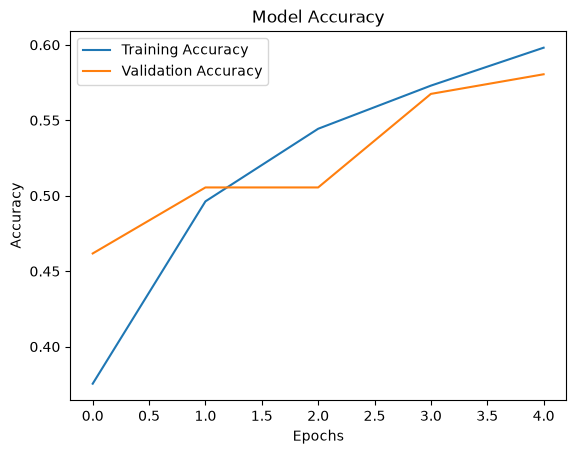

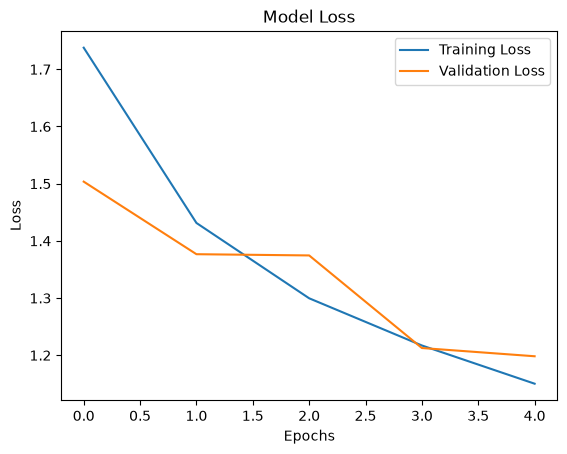

In [3]:

# 1. Import libraries
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# --------------------------------
# STAGE 1: LOAD AND PREPROCESS DATA
# --------------------------------

# Load CSV file
data = pd.read_csv("cifar-10.csv")

# Separate images and labels
x = data.drop("label", axis=1).values
y = data["label"].values

# Normalize pixel values
x = x / 255.0

# Reshape images into 32x32 RGB images
x = x.reshape(-1, 32, 32, 3)

# Split training and testing data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


# --------------------------------
# STAGE 2: DEFINE CNN MODEL
# --------------------------------

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# --------------------------------
# STAGE 3: TRAIN THE MODEL
# --------------------------------

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)


# --------------------------------
# STAGE 4: EVALUATE PERFORMANCE
# --------------------------------

loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


# Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# Plot loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [ ]:
# Practical 2A – CNN for CIFAR-10 Image Classification



Medium difficulty

CNN practical



This practical is very important because it introduces CNN (Convolutional Neural Network), which is specially designed for image classification.

Your practical statement asks you to divide the implementation into four stages:

1. Loading and preprocessing image data.
2. Defining the CNN architecture.
3. Training the CNN model.
4. Estimating the model's performance.

I'll explain the basics first, then every part of your code, and finally the questions an examiner can ask.

# 1. First understand the practical

## What is CIFAR-10?

[Khan Academy](https://images.openai.com/static-rsc-4/KsLVGWO_kpQvMLwmTyCkvn-D82brrwm_qjWfPk5ngAzTjmsnmbZCvdTnN2S9U5i-KRydXTZvhpA1GW8IP-UR0bRDtJnLoCOmFjIsKXQ9PVzIpL7iNJAZODA96CGoAVzFZcKrKecy3IS3pzi4PBCZauUL33lDVrw3J7eO7pWY0ag?purpose=inline)

CIFAR-10 is an image dataset containing 60,000 colour images divided into 10 different categories.

| Class number | Image category |
| ------------ | -------------- |
| 0            | Airplane       |
| 1            | Automobile     |
| 2            | Bird           |
| 3            | Cat            |
| 4            | Deer           |
| 5            | Dog            |
| 6            | Frog           |
| 7            | Horse          |
| 8            | Ship           |
| 9            | Truck          |

Each image has:

- Height = 32 pixels
- Width = 32 pixels
- Channels = 3 (Red, Green, Blue)

Therefore, one image has dimensions:

\\[ 32 \times 32 \times 3 \\]

What is the main objective?

We want to train a CNN model that looks at an image and predicts which of the 10 categories it belongs to.

For example:

- Input: Image of a cat.
- Output: Cat.

## What is CNN?

CNN stands for Convolutional Neural Network.

It is a type of deep learning model mainly used for image processing and image classification.

A normal FNN takes flattened pixel values as input. A CNN works directly with the image's height, width and colour channels.

CNN automatically learns important features such as:

- Edges
- Lines
- Shapes
- Patterns
- Objects

For example, it may learn the shape of ears, eyes and a face to help identify a cat.

## FNN vs CNN

| FNN                                           | CNN                                           |
| --------------------------------------------- | --------------------------------------------- |
| Fully Connected Neural Network                | Convolutional Neural Network                  |
| Uses flattened input                          | Uses image dimensions                         |
| Does not naturally preserve spatial structure | Preserves spatial information in early layers |
| Uses Dense layers                             | Uses Conv2D, Pooling and Dense layers         |
| General-purpose classification                | Particularly useful for images                |

Remember: CNN is generally better suited for image classification than a simple FNN.

# 2. Stage 1 – Loading and preprocessing data

Let's understand the code line by line.

```
import pandas as pdimport numpy as npimport tensorflow as tfimport matplotlib.pyplot as plt
```

These are the libraries used in our program.

| Library    | Purpose                              |
| ---------- | ------------------------------------ |
| pandas     | Loads and handles CSV files          |
| numpy      | Works with arrays and numerical data |
| tensorflow | Builds and trains the CNN            |
| matplotlib | Displays graphs                      |

### Load the dataset

```
data = pd.read_csv("cifar-10.csv")
```

- `pd.read_csv()` reads the CSV file.
- The dataset is stored in the variable `data`.

Your CSV file should contain:

- A `label` column.
- 3,072 pixel columns for each image.

Why 3,072?

\\[ 32 \times 32 \times 3 = 3072 \\]

### Separate images and labels

```
x = data.drop("label", axis=1).valuesy = data["label"].values
```

Here, we separate the dataset into two parts.

`x` – Input images

```
x = data.drop("label", axis=1).values
```

This removes the label column and stores only the pixel values.

`y` – Output labels

```
y = data["label"].values
```

This stores the category of each image.

For example:

- `x` contains the pixels of a cat.
- `y` contains the label `3`, representing a cat.

Remember:

- X = Input data.
- Y = Correct output or label.

### Normalize pixel values

```
x = x / 255.0
```

Pixel values normally range from 0 to 255.

| Pixel value | Meaning            |
| ----------- | ------------------ |
| 0           | Black              |
| 255         | Maximum brightness |
| 128         | Medium brightness  |

We divide every pixel by 255 to convert the values into the range 0 to 1.

For example:

\\[ \frac{128}{255}=0.502 \\]

Why normalize?

It helps the neural network train more effectively by keeping the input values within a smaller, consistent range.

### Reshape images

```
x = x.reshape(-1, 32, 32, 3)
```

This is one of the most important lines in this practical.

Initially, each image is represented as a flat array containing 3,072 pixel values.

But CNN expects images in this format:

\\[ (\text{Number of images}, 32, 32, 3) \\]

So we reshape the data into:

- 32 = Image height.
- 32 = Image width.
- 3 = RGB colour channels.
- `-1` = Automatically calculate the number of images.

Why do we reshape?

Because CNN works with image dimensions, not just a flat list of pixel values.

### Split training and testing data

```
from sklearn.model_selection import train_test_splitx_train, x_test, y_train, y_test = train_test_split(    x, y, test_size=0.2, random_state=42)
```

We divide the dataset into training and testing data.

- Training data: 80%
- Testing data: 20%

`test_size=0.2` means 20% of the dataset is reserved for testing.

`random_state=42` ensures that the same random split is produced when you run the code again.

Why split the dataset?

We train the model using training data and check how well it performs on unseen testing data.

```
print("Training data:", x_train.shape)print("Testing data:", x_test.shape)
```

This displays the dimensions of the training and testing datasets.

For 60,000 images, you should get:

```
Training data: (48000, 32, 32, 3)
Testing data: (12000, 32, 32, 3)
```

# 3. Stage 2 – Define CNN model architecture

This is the most important part of the practical.

First, understand the architecture:

## CNN architecture

Input image

# 32 × 32 × 3

RGB image

Conv2D – 32 filters

Extracts image features

MaxPooling2D – 2 × 2

Reduces image dimensions

Conv2D – 64 filters

Extracts more complex features

MaxPooling2D – 2 × 2

Further reduces dimensions

Flatten

Converts feature maps into a 1D vector

Dense – 128 neurons

Learns from extracted features

Dense – 10 neurons

Softmax classification

Predicted image class

Now let's understand each layer.

### A. Sequential model

```
model = tf.keras.Sequential([
```

`Sequential` means we create a model by adding layers one after another.

The data passes through each layer in sequence.

### B. Input layer

```
tf.keras.layers.Input(shape=(32, 32, 3)),
```

This tells the model that every input image has:

- 32 pixels in height.
- 32 pixels in width.
- 3 colour channels.

### C. First convolution layer

```
tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
```

This is the first convolution layer.

Let's break it down:

- `Conv2D`: Performs convolution on a 2D image.
- `32`: Uses 32 filters.
- `(3,3)`: Each filter has a size of 3 × 3.
- `relu`: Activation function.

What is a filter?

A filter is a small matrix that moves across an image and detects patterns.

For example, it can detect edges, lines and textures.

[Seeing the World: A Beginner's Guide to Convolutional Neural Networks (CNNs) with PyTorch - DEV Community](https://images.openai.com/static-rsc-4/UKh6bhtudbxYkDnLFlnoW-AUte75pmKXEyUY1J3zbEhn1PaPtCWSklj14RTJACIxMuF0b7Bn3eaeUzMNwIvd2YjXGiM1j0anxZgAJbJS_xQ9iG_HS3-BfRDvYHz60Sgb-uzz55ePnLgGbkCEbpt6QZA8qRQT96Uc__80wEMYNnU?purpose=inline)

[dev.to](https://dev.to/saadmanrafat/seeing-the-world-a-beginners-guide-to-convolutional-neural-networks-cnns-with-pytorch-593c?utm_source=chatgpt.com)

What is ReLU?

ReLU stands for Rectified Linear Unit.

Its formula is:

\\[ f(x)=\max(0,x) \\]

In simple words:

- If the value is negative, it becomes 0.
- If the value is positive, it remains unchanged.

### D. First MaxPooling layer

```
tf.keras.layers.MaxPooling2D((2, 2)),
```

MaxPooling reduces the size of the feature maps.

It takes a 2 × 2 area and keeps only the maximum value.

For example:

Before pooling

4 × 4 values

After pooling

2 × 2 maximum values

Why do we use MaxPooling?

1. Reduces image dimensions.
2. Reduces computation.
3. Keeps important features.
4. Helps the model focus on the strongest features.

### E. Second convolution layer

```
tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
```

This layer uses 64 filters instead of 32.

Why?

The first convolution layer learns simpler features, while deeper convolution layers can learn more complex patterns by combining earlier features.

### F. Second MaxPooling layer

```
tf.keras.layers.MaxPooling2D((2, 2)),
```

Again, it reduces the feature map dimensions.

### G. Flatten layer

```
tf.keras.layers.Flatten(),
```

Convolution and pooling produce multidimensional feature maps.

But Dense layers expect one-dimensional input.

Flatten converts the feature maps into a single long vector.

For this model, using the default valid padding:

- Input: 32 × 32 × 3
- First convolution: 30 × 30 × 32
- First pooling: 15 × 15 × 32
- Second convolution: 13 × 13 × 64
- Second pooling: 6 × 6 × 64
- Flatten: 2,304 values

### H. Dense layer

```
tf.keras.layers.Dense(128, activation='relu'),
```

This layer contains 128 neurons.

It learns combinations of the features extracted by the CNN.

### I. Output layer

```
tf.keras.layers.Dense(10, activation='softmax')
```

This is the final classification layer.

Why 10 neurons?

Because CIFAR-10 has 10 categories.

What is Softmax?

Softmax converts the model's output values into probabilities.

For example:

| Category      | Example probability |
| ------------- | ------------------- |
| Cat           | 0.75                |
| Dog           | 0.15                |
| Bird          | 0.05                |
| Other classes | 0.05                |

The class with the highest probability is selected as the prediction.

### J. Compile the model

```
model.compile(    optimizer='adam',    loss='sparse_categorical_crossentropy',    metrics=['accuracy'])
```

Before training, we configure three things.

| Term      | Meaning                                      |
| --------- | -------------------------------------------- |
| Optimizer | Updates model weights to improve predictions |
| Loss      | Measures how wrong the predictions are       |
| Accuracy  | Measures how many predictions are correct    |

Optimizer: Adam

Adam is an optimization algorithm that adjusts the model's weights during training.

Loss: Sparse categorical crossentropy

Used when we have multiple classes and labels are represented as integers (0 to 9).

Metrics: Accuracy

Measures the percentage of correct predictions.

# 4. Stage 3 – Train the CNN model

```
history = model.fit(    x_train,    y_train,    epochs=5,    batch_size=64,    validation_split=0.1)
```

This command starts training the CNN model.

Let's understand each parameter.

| Parameter              | Meaning                                  |
| ---------------------- | ---------------------------------------- |
| `x_train`              | Training images                          |
| `y_train`              | Correct training labels                  |
| `epochs=5`             | Model sees the training dataset 5 times  |
| `batch_size=64`        | Processes 64 images in one batch         |
| `validation_split=0.1` | Uses 10% of training data for validation |

### What is an epoch?

One epoch means the model has gone through the entire training dataset once.

If we have 48,000 training images:

- Epoch 1: Model sees all 48,000 images.
- Epoch 2: Model sees all 48,000 images again.
- Epoch 5: Model has completed five passes.

### What is batch size?

Batch size is the number of images processed together before the model updates its weights.

Here:

```
batch_size=64
```

It processes 64 images in one batch.

### What is validation data?

Validation data is used to check how well the model performs during training.

Here:

```
validation_split=0.1
```

10% of the training data is used for validation.

For 48,000 training images:

- Training: 43,200 images.
- Validation: 4,800 images.

### What is history?

```
history = model.fit(...)
```

`history` stores the training results, such as:

- Training accuracy.
- Validation accuracy.
- Training loss.
- Validation loss.

We use these values to draw graphs later.

# 5. Stage 4 – Evaluate model performance

### Evaluate the model

```
loss, accuracy = model.evaluate(x_test, y_test)
```

This tests the trained model using unseen test images.

It returns two values:

- `loss`: How wrong the model's predictions are.
- `accuracy`: Percentage of correct predictions.

```
print("Test Loss:", loss)print("Test Accuracy:", accuracy)
```

Important: TensorFlow normally returns accuracy as a decimal between 0 and 1.

For example:

- Accuracy = 0.70 means 70%.
- Accuracy = 0.85 means 85%.

If you want to display it as a percentage, use:

```
print("Test Accuracy:", accuracy * 100, "%")
```

### Plot accuracy graph

```
plt.plot(history.history['accuracy'], label='Training Accuracy')plt.plot(history.history['val_accuracy'], label='Validation Accuracy')plt.title("Model Accuracy")plt.xlabel("Epochs")plt.ylabel("Accuracy")plt.legend()plt.show()
```

This graph displays training and validation accuracy across the epochs.

[Akansha Saxena         |         Day 8: Build a simple CNN for CIFAR-10 image classification](https://images.openai.com/static-rsc-4/0UfQiWa5LEcOLSYR1Lp_26tmMjUBVoirsxnmmLCQLdM7V7sYtXbtW24m2lB9HbgHQDIMp7mYpW7wUzeb1zCCdPduL4_REXOk0Pn50G9RhKrMJAoh8a3V_P-d1m-AnNWM4_oC6BGswrnBJGQW7ZSwArp0_FExSHIoHEhhInlCtQg?purpose=inline)

[akanshasaxena.com](https://akanshasaxena.com/challenge/deep-learning/day-8/?utm_source=chatgpt.com)

- X-axis: Epochs.
- Y-axis: Accuracy.
- Training accuracy: Performance on training data.
- Validation accuracy: Performance on validation data.

Ideally, both accuracy curves should improve and stay reasonably close.

### Plot loss graph

```
plt.plot(history.history['loss'], label='Training Loss')plt.plot(history.history['val_loss'], label='Validation Loss')plt.title("Model Loss")plt.xlabel("Epochs")plt.ylabel("Loss")plt.legend()plt.show()
```

This graph displays training and validation loss.

[How to Classify the Images of the Cifar-10 Dataset using CNN?](https://images.openai.com/static-rsc-4/DB88KIkn5wiL53nHibYeHItBl3kuB_0OdUtW8_kPHuAh3OjlpGFCKUey6wnk1CbNwKa0cvViAVWBKNBVRDTmIrb8fzQB73AVH3s6CLWl-bI1X9hAPgFCLIdw55qoNpSnVBtsuMyoX0BFEp1V3ZvubCu40uRco-MwNQgVwCcRvoQ?purpose=inline)

[analyticsvidhya.com](https://www.analyticsvidhya.com/blog/2022/09/how-to-classify-the-images-of-the-cifar-10-dataset-using-cnn/?utm_source=chatgpt.com)

Ideally:

- Training loss decreases.
- Validation loss also decreases.
- A large gap between them can indicate overfitting.

What is overfitting?

Overfitting happens when a model performs very well on training data but performs poorly on unseen data.

# 6. Most important viva questions and answers

These are the questions I recommend preparing first.

## Basic questions

Q1. What is CNN?

CNN stands for Convolutional Neural Network. It is a deep learning model mainly used for image classification and image processing.

Q2. Why do we use CNN instead of FNN for image classification?

CNN extracts spatial features such as edges, shapes and patterns from images. FNN requires flattened images and does not naturally preserve their spatial structure.

Q3. What is CIFAR-10?

CIFAR-10 is a dataset containing 60,000 colour images of size 32 × 32 pixels, divided into 10 classes.

Q4. How many output neurons are used in this practical?

10 output neurons because CIFAR-10 contains 10 classes.

Q5. What is the input shape?

32 × 32 × 3, where 32 is height, 32 is width and 3 represents RGB channels.

## CNN architecture questions

Q6. What is convolution?

Convolution is an operation in which filters move over an image to extract features such as edges and patterns.

Q7. What is a filter?

A filter is a small matrix that moves across an image and detects specific features.

Q8. What is Conv2D?

Conv2D is a convolutional layer that applies filters to a 2D image.

Q9. Why do we use 32 and 64 filters?

They determine how many feature maps are learned by the convolution layers.

Q10. What is MaxPooling?

MaxPooling reduces the dimensions of feature maps by selecting the maximum value from a small region.

Q11. What is Flatten?

Flatten converts multidimensional feature maps into a one-dimensional vector.

Q12. What is ReLU?

ReLU is an activation function that converts negative values to zero and keeps positive values unchanged.

Q13. What is Softmax?

Softmax converts output values into probabilities for multiple classes.

## Training questions

Q14. What is an epoch?

One epoch means the model has gone through the entire training dataset once.

Q15. What is batch size?

Batch size is the number of training images processed together before the model updates its weights.

Q16. What is Adam?

Adam is an optimizer used to update the model's weights and reduce the loss.

Q17. What is sparse categorical crossentropy?

It is a loss function used for multiclass classification when the target labels are integers.

Q18. What is validation data?

Validation data is used to monitor the model's performance during training.

Q19. What is overfitting?

Overfitting occurs when the model performs well on training data but poorly on unseen data.

## Performance questions

Q20. What is accuracy?

Accuracy is the percentage of correctly predicted images.

Q21. What is loss?

Loss measures the difference between the model's predictions and the actual labels.

Q22. Why do we use graphs?

Graphs help us understand how training and validation accuracy and loss change across epochs.

Q23. What is the difference between training and testing data?

Training data teaches the model. Testing data evaluates the model on unseen examples after training.

# 7. Your practical explanation to the examiner

If the examiner asks you to explain the entire practical, you can say this:

"In this practical, I have implemented a Convolutional Neural Network for classifying the CIFAR-10 image dataset.

First, I loaded the dataset from a CSV file using Pandas. I separated the images and labels, normalized the pixel values between 0 and 1, and reshaped the images into 32 × 32 RGB format.

Then, I divided the dataset into 80% training data and 20% testing data.

In the second stage, I created a CNN model using TensorFlow and Keras. The model contains two convolution layers with 32 and 64 filters, two MaxPooling layers, a Flatten layer, a Dense layer with 128 neurons, and an output layer with 10 neurons using Softmax activation.

I compiled the model using the Adam optimizer, sparse categorical crossentropy loss function and accuracy metric.

In the third stage, I trained the model for 5 epochs with a batch size of 64 and used 10% of the training data for validation.

Finally, I evaluated the model using testing data and plotted training and validation accuracy and loss graphs to understand its performance."

&#x20;Copy explanation

# 8. Important differences between Practical 1C and 2A

You have already studied FNN on CIFAR-10 in Practical 1C. This comparison will help you understand what changed.

| Practical 1C – FNN                    | Practical 2A – CNN                               |
| ------------------------------------- | ------------------------------------------------ |
| Uses flattened 3,072 pixel values     | Uses 32 × 32 × 3 images                          |
| Dense layers                          | Conv2D and pooling layers                        |
| Learns from flattened features        | Extracts image features                          |
| No convolution                        | Uses convolution                                 |
| No pooling                            | Uses MaxPooling                                  |
| Flattening happens before Dense input | Flattening happens after convolution and pooling |

The most important difference: Practical 1C uses a fully connected network, whereas Practical 2A uses convolution and pooling to extract features from images.

# 9. Quick revision before your practical exam

## Practical 2A – Cheat sheet

| Question          | Answer                          |
| ----------------- | ------------------------------- |
| Dataset           | CIFAR-10                        |
| Total images      | 60,000                          |
| Classes           | 10                              |
| Image size        | 32 × 32                         |
| Colour channels   | 3 (RGB)                         |
| Input shape       | 32 × 32 × 3                     |
| Train/test split  | 80% / 20%                       |
| Conv2D filters    | 32 and 64                       |
| Filter size       | 3 × 3                           |
| Pooling size      | 2 × 2                           |
| Dense neurons     | 128                             |
| Output neurons    | 10                              |
| Hidden activation | ReLU                            |
| Output activation | Softmax                         |
| Optimizer         | Adam                            |
| Loss              | Sparse categorical crossentropy |
| Epochs            | 5                               |
| Batch size        | 64                              |
| Validation split  | 10%                             |

## 10. Test yourself – Viva practice

Try answering these without looking at the explanations.

6 viva questions

0/6 answered

1\. Why do we reshape the CIFAR-10 images into (32, 32, 3)?

Because CNN expects image dimensions

Because we need 10 classes

Because Adam requires it



2\. What is the purpose of MaxPooling?

Increase image size

Reduce feature map dimensions

Convert labels into numbers



3\. Why does the output layer have 10 neurons?

There are 10 epochs

There are 10 classes

There are 10 filters



4\. What does Flatten do?

Converts feature maps into a 1D vector

Normalizes images

Splits the dataset



5\. What does epochs=5 mean?

Train on 5 images

Use 5 classes

Pass through the training dataset 5 times



6\. Which loss function is used in this practical?

Mean squared error

Sparse categorical crossentropy

Binary crossentropy



Check my answers

One important practical note: Your code assumes `cifar-10.csv` contains 3,072 pixel columns in the correct RGB order, plus a `label` column. If the images are stored in a different column order, the reshape may produce incorrect-looking images. Also, if you get an error during reshaping, check that there are exactly 3,072 pixel columns.

For your exam, focus especially on Conv2D, filters, MaxPooling, Flatten, ReLU, Softmax, epoch, batch size, and overfitting. These are the concepts most directly connected to your code.